# Latency comparison: Fast vs Best vs iHub

Compare the **same 2,000 orders** using the saved v2 benchmark. Every chart includes all orders, including the 183 iHub fill policy exceptions: this notebook measures timing, not packing quality.

**Measurement scope:** Fast and Best are local solver runtimes; iHub is the historical full service round trip, including network/service overhead. These observations describe the saved run, not a controlled solver speed comparison. Each system has one observation per order; P95 is across orders, not repeated trials. Best runtime includes its Fast baseline and additional search.

This notebook loads saved results only. Run all cells without running 2,000 solver calls or contacting iHub. The attached v1 data uses a different carton catalogue and is deliberately not mixed with these v2 timings.


In [1]:
import csv
import hashlib
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'notebooks/artifacts/benchmark_2000_best_vs_ihub.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook within the project repository.')
sys.path.insert(0, str(ROOT / 'notebooks'))
from benchmark_comparison import read_benchmark

CSV_PATH = ROOT / 'notebooks/artifacts/benchmark_2000_best_vs_ihub.csv'
rows = sorted(read_benchmark(CSV_PATH), key=lambda row: int(row['order_id']))
SYSTEMS = ('Fast', 'Best', 'iHub')
FIELDS = ('fast_runtime_ms', 'best_runtime_ms', 'ihub_latency_ms')
times = {name: np.array([float(row[field]) for row in rows])
         for name, field in zip(SYSTEMS, FIELDS)}
for name, values in times.items():
    assert len(values) == 2000 and np.all(np.isfinite(values)) and np.all(values > 0), name
order_ids = np.array([int(row['order_id']) for row in rows])
COLORS = {'Fast': '#087f8c', 'Best': '#d97745', 'iHub': '#536273'}
plt.rcParams.update({'figure.figsize': (11, 4.5), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.titlelocation': 'left'})
display(Markdown(f'**Loaded:** {len(rows):,} unique matched orders. No exclusions.  \n**Source:** `{CSV_PATH.relative_to(ROOT)}`  \n**SHA256:** `{hashlib.sha256(CSV_PATH.read_bytes()).hexdigest()}`'))

def table(headers, records):
    display(Markdown('| ' + ' | '.join(headers) + ' |\n| ' + ' | '.join(['---'] * len(headers))
                     + ' |\n' + '\n'.join('| ' + ' | '.join(map(str, row)) + ' |' for row in records)))

def finish(ax, ylabel='Latency (ms)'):
    ax.set_ylabel(ylabel)
    ax.grid(axis='y', alpha=.15)
    ax.set_axisbelow(True)
    plt.tight_layout()
    plt.show()


**Loaded:** 2,000 unique matched orders. No exclusions.  
**Source:** `notebooks/artifacts/benchmark_2000_best_vs_ihub.csv`  
**SHA256:** `2338ed1523bcdb9cbcc5f2b38f2fdaf22800c7c21752d68ba28eab8561de9937`

## 1. Typical latency and tail latency

Median describes a typical order; P95 is the latency at or below which 95% of these orders fall. Percentiles use NumPy's linear interpolation. The chart starts at zero; the table retains exact values rounded to two decimals.


| System | Orders | Mean ms | Median ms | P90 ms | P95 ms | P99 ms | Max ms |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Fast | 2000 | 2.37 | 1.05 | 3.89 | 7.61 | 24.35 | 41.92 |
| Best | 2000 | 62.84 | 19.86 | 104.47 | 266.75 | 588.78 | 4,920.80 |
| iHub | 2000 | 226.20 | 187.25 | 368.84 | 442.01 | 648.62 | 2,614.53 |

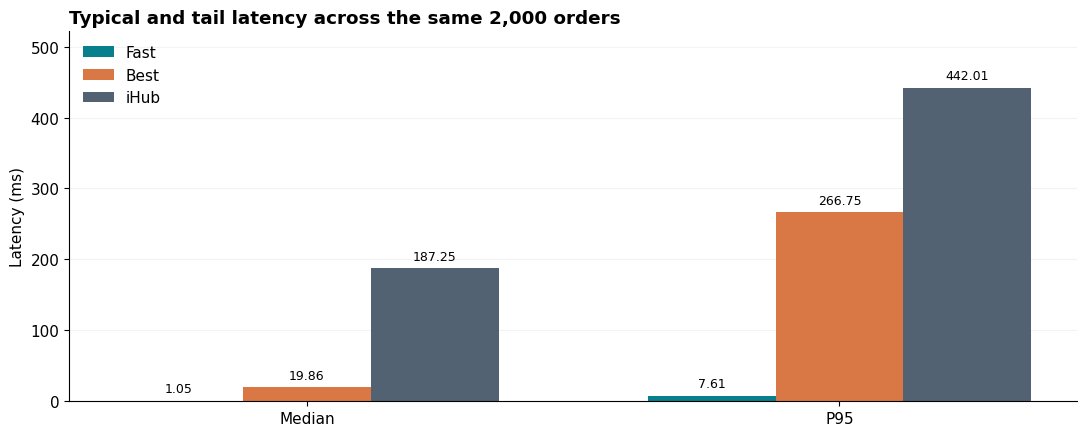

In [2]:
stats = {name: [np.mean(v), *np.percentile(v, [50, 90, 95, 99]), np.max(v)]
         for name, v in times.items()}
table(['System', 'Orders', 'Mean ms', 'Median ms', 'P90 ms', 'P95 ms', 'P99 ms', 'Max ms'],
      [[name, len(rows), *[f'{x:,.2f}' for x in stats[name]]] for name in SYSTEMS])
fig, ax = plt.subplots()
x = np.arange(2)
for i, name in enumerate(SYSTEMS):
    values = [stats[name][1], stats[name][3]]
    bars = ax.bar(x + (i - 1) * .24, values, .24, label=name, color=COLORS[name])
    ax.bar_label(bars, fmt='%.2f', padding=4, fontsize=9)
ax.set_xticks(x, ['Median', 'P95'])
ax.set_ylim(0, max(stats[n][3] for n in SYSTEMS) * 1.18)
ax.set_title('Typical and tail latency across the same 2,000 orders')
ax.legend(frameon=False)
finish(ax)


## 2. Full latency distribution

The cumulative distribution shows every observation. At any latency on the horizontal axis, the vertical value gives the percentage of orders completed within that time. The logarithmic axis keeps submillisecond and multisecond observations visible together.


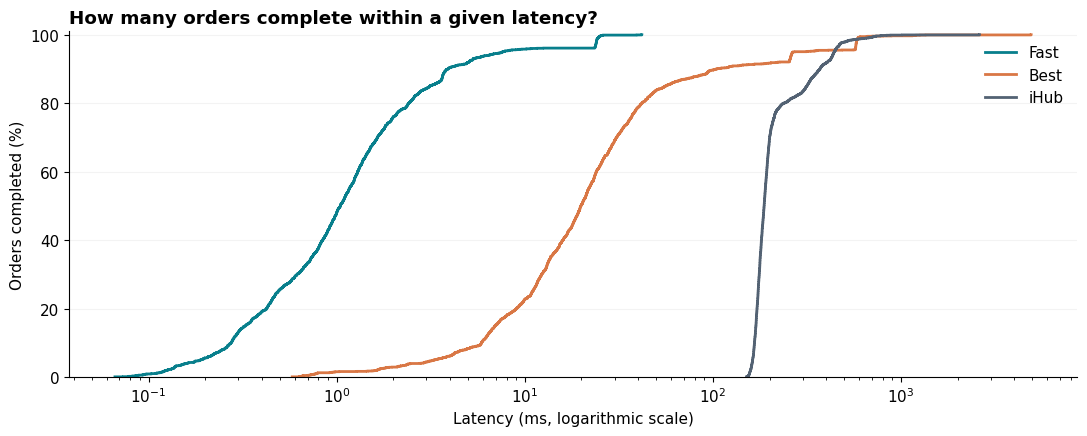

In [3]:
fig, ax = plt.subplots()
for name, values in times.items():
    ax.step(np.sort(values), np.arange(1, len(values) + 1) / len(values) * 100,
            where='post', label=name, color=COLORS[name], linewidth=2)
ax.set_xscale('log')
ax.set_xlabel('Latency (ms, logarithmic scale)')
ax.set_ylim(0, 101)
ax.set_title('How many orders complete within a given latency?')
ax.legend(frameon=False)
finish(ax, 'Orders completed (%)')


## 3. All 2,000 orders in one scatter plot

Each order contributes three points: Fast (teal), Best (orange), and iHub (slate). The horizontal axis identifies the same 2,000 orders; the vertical axis shows latency on a logarithmic scale. Transparency makes overlapping observations easier to see. This shows the spread of observations, rather than frequency counts grouped into bins. Order ID is not chronological time.


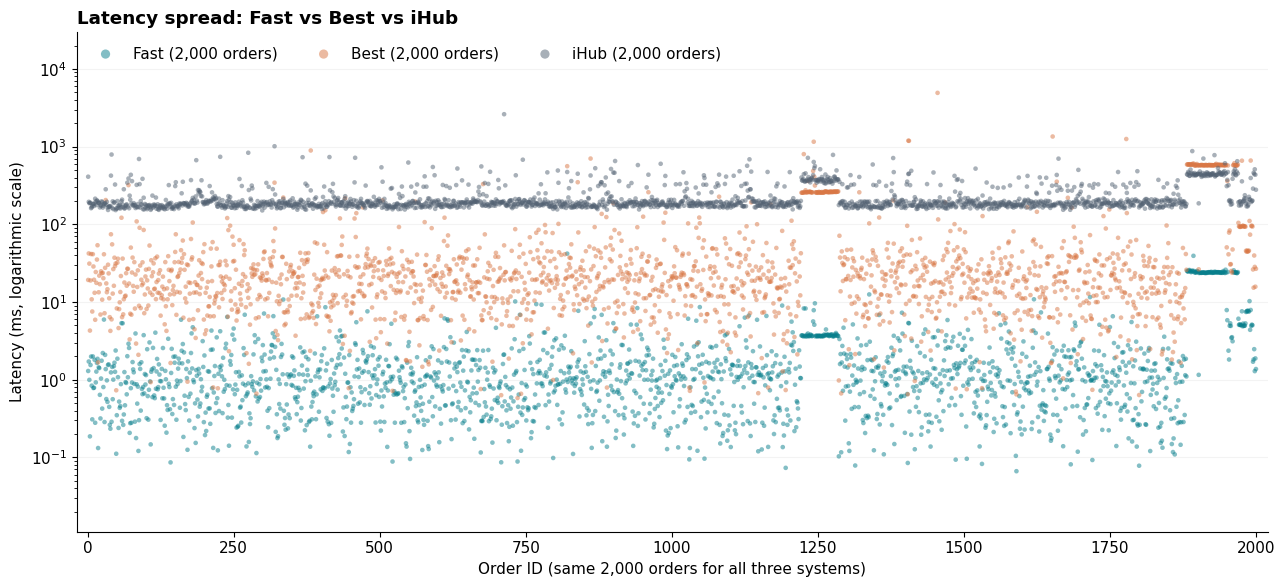

In [4]:
fig, ax = plt.subplots(figsize=(13, 6))
for name in SYSTEMS:
    ax.scatter(order_ids, times[name], s=11, alpha=.5, color=COLORS[name],
               label=f'{name} (2,000 orders)', edgecolors='none', rasterized=True)
ax.set_yscale('log')
ax.set_xlabel('Order ID (same 2,000 orders for all three systems)')
ax.set_title('Latency spread: Fast vs Best vs iHub')
ax.legend(frameon=False, loc='upper left', ncol=3, markerscale=2)
ax.margins(x=.01, y=.16)
finish(ax, 'Latency (ms, logarithmic scale)')


## 4. Matched order comparison against iHub

Each panel pairs our recorded runtime with iHub's recorded latency for the **same order**. Points below the equality line have a lower observed local runtime. This does not isolate algorithm efficiency because the measurement boundaries differ.


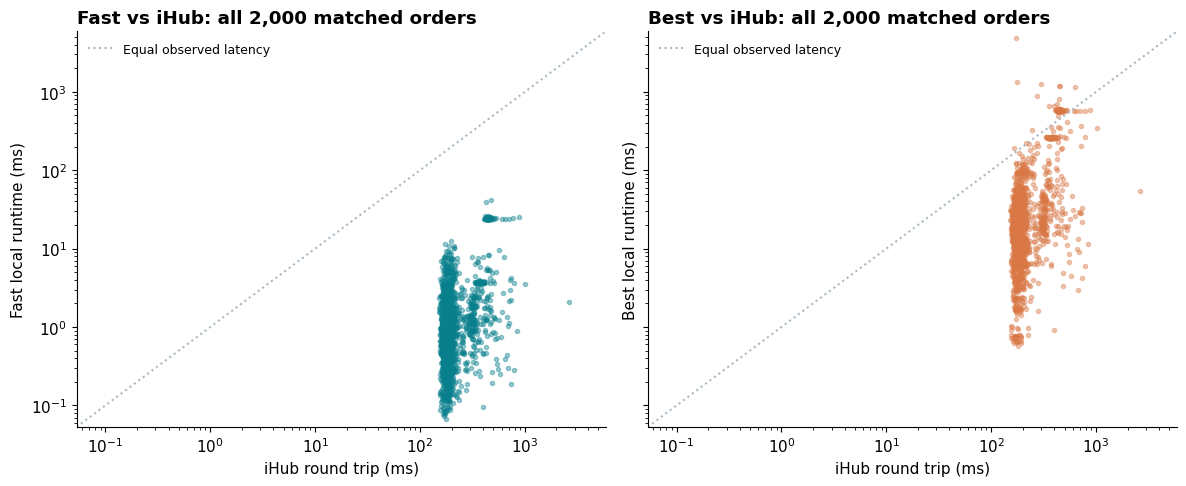

| Local mode | Lower observed ms than iHub | Equal | Higher observed ms than iHub | Median paired iHub / local ratio |
| --- | --- | --- | --- | --- |
| Fast | 2000 | 0 | 0 | 191.39× |
| Best | 1912 | 0 | 88 | 9.82× |

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
lo = min(v.min() for v in times.values()) * .8
hi = max(v.max() for v in times.values()) * 1.2
for ax, name in zip(axes, ('Fast', 'Best')):
    ax.scatter(times['iHub'], times[name], s=9, alpha=.4, color=COLORS[name], rasterized=True)
    ax.plot([lo, hi], [lo, hi], color='#aab8c2', linestyle=':', label='Equal observed latency')
    ax.set(xscale='log', yscale='log', xlim=(lo, hi), ylim=(lo, hi),
           xlabel='iHub round trip (ms)', ylabel=f'{name} local runtime (ms)')
    ax.set_title(f'{name} vs iHub: all 2,000 matched orders')
    ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()
table(['Local mode', 'Lower observed ms than iHub', 'Equal', 'Higher observed ms than iHub',
       'Median paired iHub / local ratio'],
      [[name, int(np.sum(times[name] < times['iHub'])),
        int(np.sum(times[name] == times['iHub'])), int(np.sum(times[name] > times['iHub'])),
        f"{np.median(times['iHub'] / times[name]):.2f}×"] for name in ('Fast', 'Best')])


## 5. Latency as order size increases

These panels retain all 2,000 observations per system. Physical item count includes Quantity. The same axes show whether difficult or large orders account for the latency tail; this is an observed association, not a controlled scaling experiment.


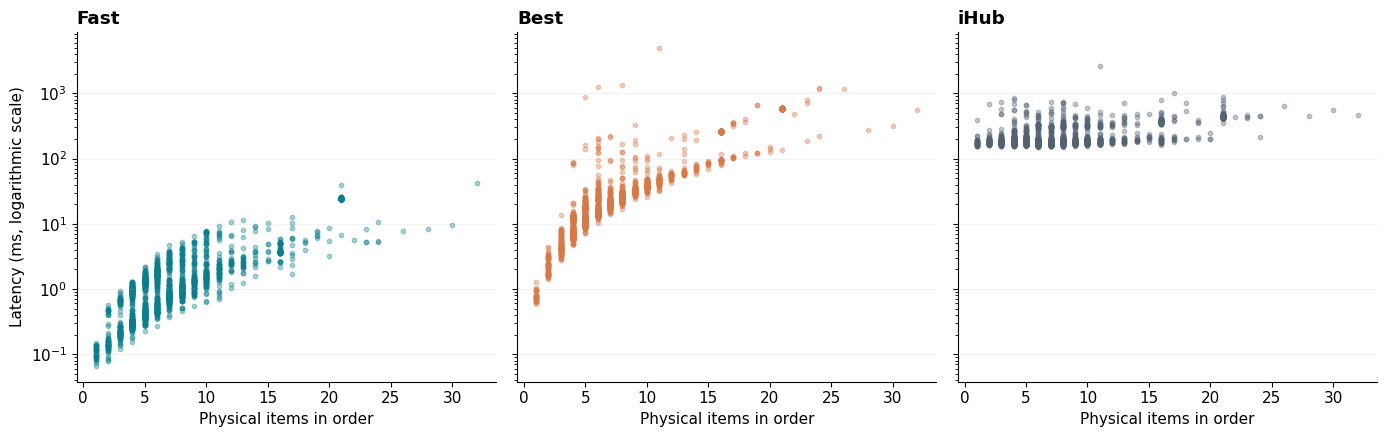

In [6]:
item_counts = np.array([int(row['physical_items']) for row in rows])
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharex=True, sharey=True)
for ax, name in zip(axes, SYSTEMS):
    ax.scatter(item_counts, times[name], s=10, alpha=.35, color=COLORS[name], rasterized=True)
    ax.set_yscale('log')
    ax.set_title(name)
    ax.set_xlabel('Physical items in order')
    ax.grid(axis='y', alpha=.15)
axes[0].set_ylabel('Latency (ms, logarithmic scale)')
fig.tight_layout()
plt.show()


## Reading and refreshing the evidence

The notebook describes the checked in benchmark; it does not rerun current solver code. A single saved run cannot establish repeatability or current production performance. Refresh the canonical benchmark using the project's existing benchmark workflow, then rerun this notebook.

For a controlled comparison, measure all systems with the same hardware and timing boundary, repeat each order, document warmup and concurrency, and separate network time from solver time where available. Packing correctness and recommendation quality remain separate evaluations in the Solver Demo.
